# Feather Stories — the unregistered stork of the Lower Prut

Goal: find the six letters on the ring of the one White Stork that is read in the field but missing from `ring_register.csv`.

Plan: look at the data, learn how letters get misread, match every read to a registered bird, see what is left over among the storks, and take a per-position consensus of the leftovers.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, itertools
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', font_scale=0.9)

D = '../task_moldova/'
obs = pd.read_csv(D + 'observations.csv', dtype={'ring_read': str})
reg = pd.read_csv(D + 'ring_register.csv')
rd = obs[obs.ring_read.notna()].reset_index(drop=True)
STORK = 'Ciconia ciconia'
print(obs.shape, reg.shape, 'reads:', len(rd))

(79968, 13) (289, 5) reads: 3023


## 1. EDA

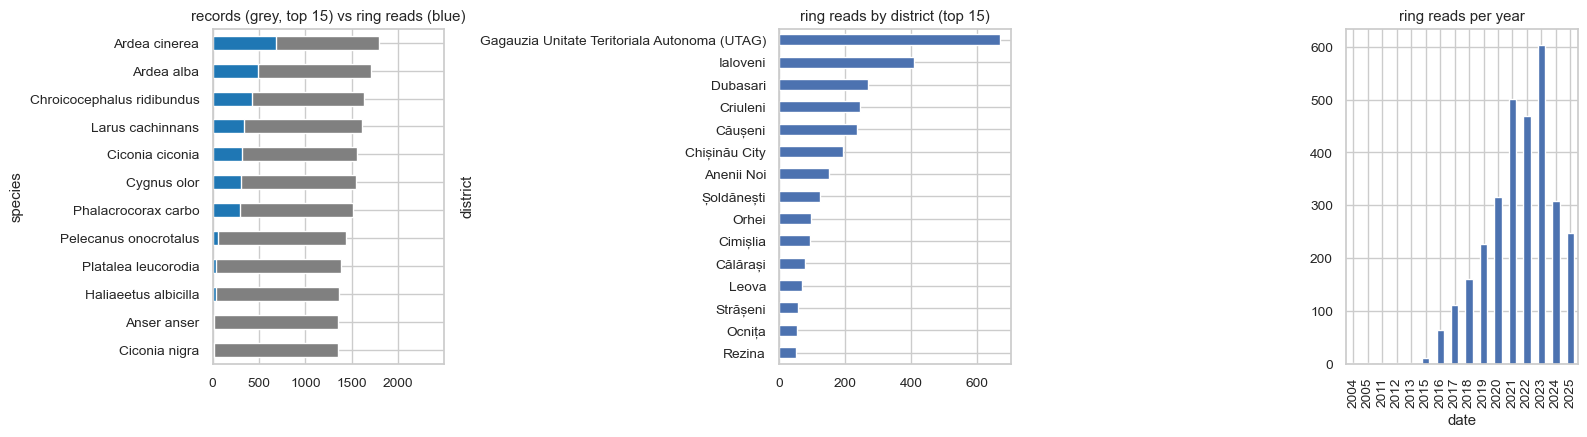

species with reads: 12 | registered birds per species:
species
Ardea cinerea                 65
Ardea alba                    54
Cygnus olor                   34
Chroicocephalus ridibundus    31
Phalacrocorax carbo           30
Ciconia ciconia               30
Larus cachinnans              29
Haliaeetus albicilla           6
Pelecanus onocrotalus          4
Ciconia nigra                  3
Platalea leucorodia            2
Anser anser                    1


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
obs.species.value_counts().head(15)[::-1].plot.barh(ax=ax[0], color='grey')
rd.species.value_counts()[::-1].plot.barh(ax=ax[0], color='tab:blue')
ax[0].set_title('records (grey, top 15) vs ring reads (blue)')
rd.district.value_counts().head(15)[::-1].plot.barh(ax=ax[1]); ax[1].set_title('ring reads by district (top 15)')
pd.to_datetime(rd.date).dt.year.value_counts().sort_index().plot.bar(ax=ax[2]); ax[2].set_title('ring reads per year')
plt.tight_layout(); plt.show()
print('species with reads:', rd.species.nunique(), '| registered birds per species:')
print(reg.species.value_counts().to_string())

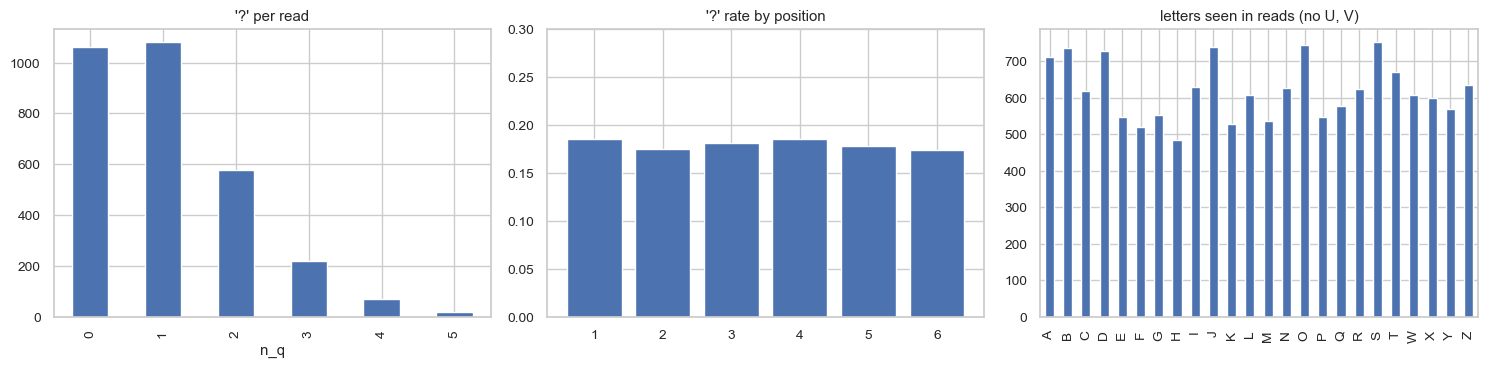

reads that equal a registered ring exactly: 95 of 3023


In [3]:
rd['n_q'] = rd.ring_read.str.count(r'\?')
pos_q = np.array([[c == '?' for c in s] for s in rd.ring_read]).mean(0)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
rd.n_q.value_counts().sort_index().plot.bar(ax=ax[0]); ax[0].set_title("'?' per read")
ax[1].bar(range(1, 7), pos_q); ax[1].set_title("'?' rate by position"); ax[1].set_ylim(0, .3)
letters = pd.Series(list(''.join(rd.ring_read).replace('?', ''))).value_counts().sort_index()
letters.plot.bar(ax=ax[2]); ax[2].set_title('letters seen in reads (no U, V)')
plt.tight_layout(); plt.show()
print('reads that equal a registered ring exactly:', rd.ring_read.isin(set(reg.ring)).sum(), 'of', len(rd))

Every read has six characters, about one `?` per read, spread evenly over positions. U and V never occur. Only ~3% of reads equal a registered ring, so readable letters are wrong a lot of the time.

## 2. Which letters get confused

First pass: match each read to the registered ring of the same species with the fewest mismatches (ignoring `?`), keep the reads where the best match clearly beats the runner-up, and count true → read letter pairs.

In [4]:
A = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'; ix = {c: i for i, c in enumerate(A)}
R = np.array([[ix.get(c, -1) for c in s] for s in rd.ring_read])
G = np.array([[ix[c] for c in s] for s in reg.ring])
cand = {s: np.where(reg.species.values == s)[0] for s in rd.species.unique()}
sp = rd.species.values

def hamming(j, rows):
    o = R[j] >= 0
    return (G[rows][:, o] != R[j][o]).sum(1)

first = []
for j in range(len(rd)):
    d = hamming(j, cand[sp[j]]); o = np.argsort(d)
    first.append((cand[sp[j]][o[0]], d[o[0]], d[o[1]] if len(o) > 1 else 9))
first = np.array(first)
sure = (first[:, 1] <= 2) & (first[:, 2] - first[:, 1] >= 2)
Cnt = np.zeros((26, 26), int)
for j in np.where(sure)[0]:
    o = R[j] >= 0
    np.add.at(Cnt, (G[first[j, 0]][o], R[j][o]), 1)
print('confident first-pass matches:', sure.sum())

confident first-pass matches: 947


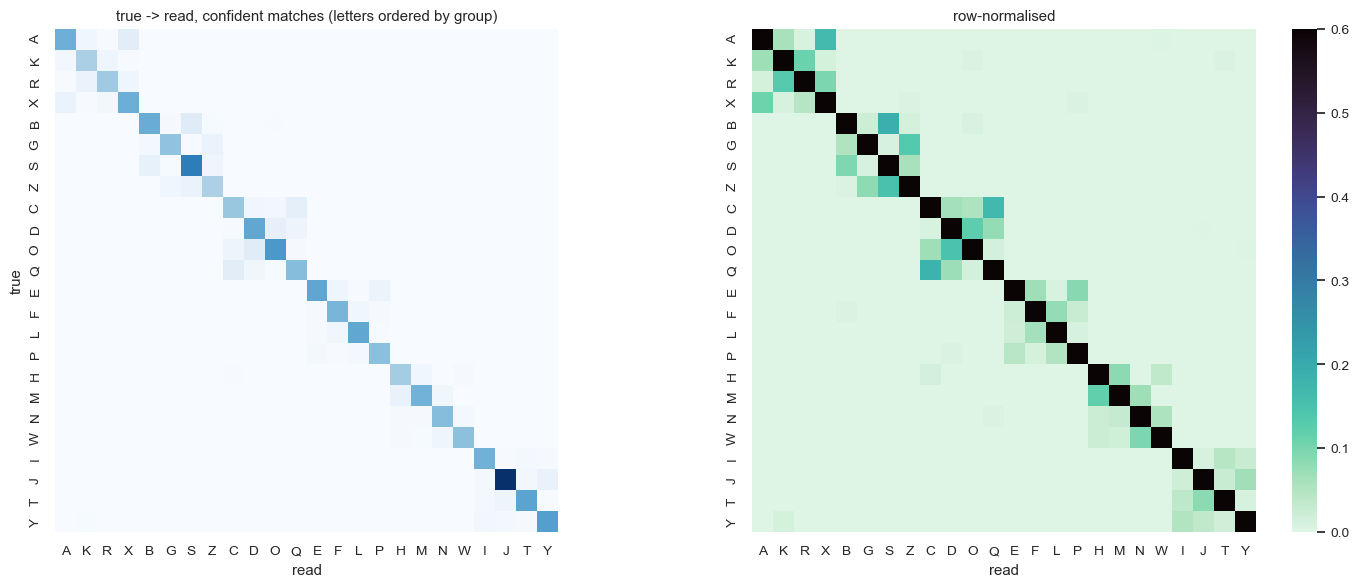

substitutions that leave the group: 17 of 851


In [5]:
GR = ['AKRX', 'BGSZ', 'CDOQ', 'EFLP', 'HMNW', 'IJTY']
order = [ix[c] for g in GR for c in g]
lab = [A[i] for i in order]
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(Cnt[np.ix_(order, order)], ax=ax[0], cmap='Blues', xticklabels=lab, yticklabels=lab, cbar=False, square=True)
ax[0].set_xlabel('read'); ax[0].set_ylabel('true'); ax[0].set_title('true -> read, confident matches (letters ordered by group)')
P = Cnt / np.maximum(Cnt.sum(1, keepdims=True), 1)
sns.heatmap(P[np.ix_(order, order)], ax=ax[1], cmap='mako_r', xticklabels=lab, yticklabels=lab, vmax=.6, square=True)
ax[1].set_title('row-normalised'); ax[1].set_xlabel('read')
plt.tight_layout(); plt.show()
gid = np.full(26, -1)
for k, g in enumerate(GR):
    for c in g: gid[ix[c]] = k
off = sum(Cnt[t, r] for t in range(26) for r in range(26) if gid[t] != gid[r])
print('substitutions that leave the group:', off, 'of', Cnt.sum() - np.trace(Cnt))

The 24 letters fall into six groups of four look-alikes: **AKRX, BGSZ, CDOQ, EFLP, HMNW, IJTY**. A misread never leaves its group. Inside a group the correct letter is only somewhat more likely than the other three, which is why plain Hamming matching works so badly.

## 3. The misreading depends on the place

Second pass: one in-group confusion matrix for everybody, EM over soft assignments of each read to the registered birds of its species. Then keep the confident assignments of non-stork reads and ask what the errors depend on: cross-validated log-likelihood of a read letter given the true letter, with the confusion table estimated per grouping key.

In [6]:
mask = ((gid[:, None] == gid[None, :]) & (gid[:, None] >= 0)) | np.eye(26, dtype=bool)
C1 = mask * .2 + np.eye(26) * .4; C1 /= C1.sum(1, keepdims=True)
for it in range(20):
    N = np.zeros((26, 26)); best1 = []
    lC = np.log(C1 + 1e-12)
    for j in range(len(rd)):
        ci = cand[sp[j]]; o = R[j] >= 0
        lp = lC[G[ci][:, o], R[j][o]].sum(1); w = np.exp(lp - lp.max()); w /= w.sum()
        best1.append((ci[w.argmax()], w.max()))
        for k, wk in zip(ci, w):
            if wk > 1e-4: np.add.at(N, (G[k][o], R[j][o]), wk)
    C1 = (N + .5) * mask; C1 /= C1.sum(1, keepdims=True)
best1 = np.array(best1)
keep = (best1[:, 1] > .99) & (sp != STORK)
rows = []
for j in np.where(keep)[0]:
    x = rd.iloc[j]; b = int(best1[j, 0])
    for p in range(6):
        if R[j, p] >= 0:
            rows.append((x.locality_id, x.district, x.observers, x.date[:4], reg.ring[b], reg.species[b], G[b, p], R[j, p]))
L = pd.DataFrame(rows, columns=['locality', 'district', 'observers', 'year', 'bird', 'species', 't', 'r'])
print('confident non-stork reads:', keep.sum(), '| letters:', len(L), '| exact letters:', round((L.t == L.r).mean(), 3))
L['none'] = 0; L['locality x observers'] = L.locality + L.observers; L['locality x year'] = L.locality + L.year
fold = np.random.default_rng(0).integers(0, 5, len(L))
cv = {}
for key in ['none', 'year', 'observers', 'species', 'district', 'locality x observers', 'locality x year', 'bird', 'locality']:
    ll = 0
    for f in range(5):
        tr, te = L[fold != f], L[fold == f]
        c3 = tr.groupby([key, 't', 'r']).size().to_dict(); c2 = tr.groupby([key, 't']).size().to_dict()
        ll += sum(np.log((c3.get((k, t, r), 0) + .5) / (c2.get((k, t), 0) + 2)) for k, t, r in zip(te[key], te.t, te.r))
    cv[key] = ll / len(L)
print(pd.Series(cv).round(3).sort_values().to_string())
print('uniform inside group would be', round(np.log(.25), 3))

confident non-stork reads: 2586 | letters: 12963 | exact letters: 0.408


year                   -1.306
none                   -1.299
observers              -1.257
species                -1.189
locality x observers   -1.061
locality x year        -1.004
district               -0.962
bird                   -0.897
locality               -0.852
uniform inside group would be -1.386


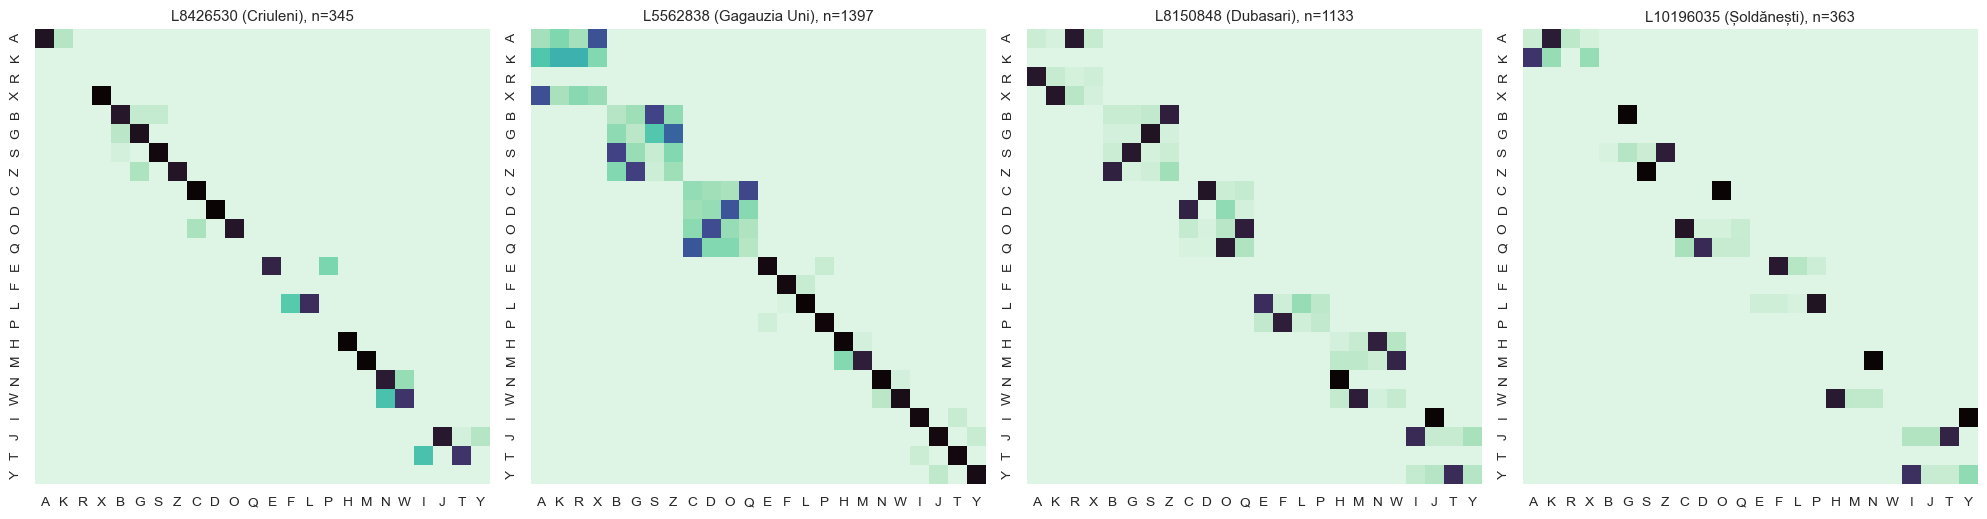

In [7]:
show = ['L8426530', 'L5562838', 'L8150848', 'L10196035']
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for a, l in zip(ax, show):
    d = L[L.locality == l]; M = np.zeros((26, 26)); np.add.at(M, (d.t, d.r), 1)
    M = M / np.maximum(M.sum(1, keepdims=True), 1)
    sns.heatmap(M[np.ix_(order, order)], ax=a, cmap='mako_r', xticklabels=lab, yticklabels=lab, cbar=False, square=True)
    a.set_title(f"{l} ({d.district.iloc[0][:12]}), n={len(d)}")
plt.tight_layout(); plt.show()

The locality (where the bird was read) is the best key, better than the bird itself or the observers. Each site has its own systematic swap inside the groups: at L8426530 reads are almost exact, at L5562838 the first three groups are swapped in pairs (A↔X, K↔R, B↔S, G↔Z, C↔Q, D↔O), at L8150848 every group is swapped, at L10196035 a different pairing is used. Observers moving between sites inherit the site's pattern.

## 4. Matching model

Each read is generated as `read letter ~ M_site[true letter]` with `M_site` a 26×26 matrix restricted to the letter groups, shrunk towards the global matrix. EM: assign every read softly to the registered birds of its species, re-estimate the site matrices, repeat. `?` carries no information.

In [8]:
loc = pd.factorize(rd.locality_id)[0]; nloc = loc.max() + 1
Mg = mask * .2 + np.eye(26) * .4; Mg /= Mg.sum(1, keepdims=True)
Ml = np.repeat(Mg[None], nloc, 0)
ALPHA = 4.0

def loglik(j, rows):
    o = R[j] >= 0
    return np.log(Ml[loc[j]][G[rows][:, o], R[j][o]] + 1e-12).sum(1)

for it in range(25):
    N = np.zeros((nloc, 26, 26)); post = []
    for j in range(len(rd)):
        ci = cand[sp[j]]; lp = loglik(j, ci); w = np.exp(lp - lp.max()); w /= w.sum()
        post.append((ci, w, lp))
        o = R[j] >= 0
        for k, wk in zip(ci, w):
            if wk > 1e-4: np.add.at(N[loc[j]], (G[k][o], R[j][o]), wk)
    Mg = (N.sum(0) + .5) * mask; Mg /= Mg.sum(1, keepdims=True)
    Ml = (N + ALPHA * Mg[None]) * mask[None]; Ml /= Ml.sum(2, keepdims=True)

prior = (gid >= 0) / 24
res = []
for j in range(len(rd)):
    ci, w, lp = post[j]; o = R[j] >= 0; M = Ml[loc[j]]
    null = sum(np.log((prior * M[:, R[j, p]]).sum()) for p in range(6) if o[p])
    res.append((reg.ring[ci[lp.argmax()]], w.max(), lp.max() - null))
rd[['best', 'p_best', 'llr']] = pd.DataFrame(res, index=rd.index)
print('reads assigned with p>0.99:', (rd.p_best > .99).sum(), 'of', len(rd))

reads assigned with p>0.99: 2905 of 3023


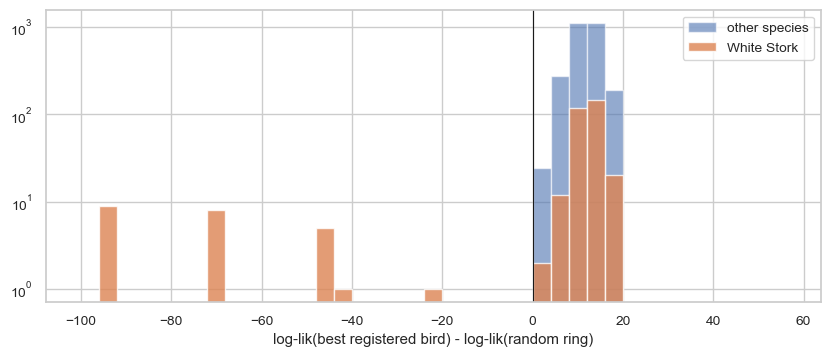

stork reads: 320 | explained worse than a random ring: 24
non-stork reads explained worse than random: 0


In [9]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.arange(-100, 60, 4)
ax.hist(rd.llr[rd.species != STORK], bins=bins, alpha=.6, label='other species')
ax.hist(rd.llr[rd.species == STORK], bins=bins, alpha=.8, label='White Stork')
ax.axvline(0, color='k', lw=.8); ax.set_yscale('log')
ax.set_xlabel('log-lik(best registered bird) - log-lik(random ring)'); ax.legend(); plt.show()
st = rd[rd.species == STORK]
print('stork reads:', len(st), '| explained worse than a random ring:', (st.llr < 0).sum())
print('non-stork reads explained worse than random:', (rd[rd.species != STORK].llr < 0).sum())

Every non-stork read and 296 of 320 stork reads are explained well by a registered bird. The 24 stork reads on the left are explained worse than a random ring. Who are they?

In [10]:
odd = st[st.llr < 0].sort_values('date')
print(odd.groupby(['locality_id', 'district', 'latitude', 'longitude']).size())
print(odd.date.min(), '->', odd.date.max(), '| distinct observers:', odd.observers.str.split('|').explode().nunique())
odd[['date', 'observers', 'ring_read']]

locality_id  district  latitude   longitude
L5819951     Cahul     45.606112  28.12088     24
dtype: int64
2016-05-21 -> 2025-08-11 | distinct observers: 24


,date,observers,ring_read
57,2016-05-21,obsr193737|obsr641647|obsr808609,AHGPW?
146,2017-05-12,obsr641647|obsr761177,RH?LWD
238,2018-04-17,obsr193737|obsr808609,RH?LWQ
281,2018-06-30,obsr761177|obsr808609,RH?LHQ
454,2019-05-04,obsr641647,RH??WQ
496,2019-06-06,obsr641647,RHGLWQ
511,2019-08-26,obsr1093220|obsr1118894|obsr1264504|obsr761177,RHGF?Q
781,2020-06-27,obsr1481045,RHGLNC
804,2020-07-26,obsr1093220|obsr1303420|obsr761177,RHGLWQ
997,2021-04-03,obsr1093220|obsr1303420|obsr1481045|obsr761177,K???WQ


All 24 come from one site, L5819951 (45.61 N, 28.12 E) in Cahul district: the Lower Prut, Beleu / Manta lakes. They span 2016–2025 and 24 different observers, and no other ring is ever read there. Checks that this is a new bird and not a registered one in disguise:

In [11]:
gpat = lambda s: ''.join('?' if c == '?' else str(gid[ix[c]]) for c in s)
odd_pat = odd.ring_read.map(gpat)
def compatible(read, ring):
    return all(a == '?' or a == b for a, b in zip(gpat(read), gpat(ring)))
hits = {r: sum(compatible(x, r) for x in odd.ring_read) for r in reg.ring}
print('group pattern of the reads:', odd_pat.value_counts().head(3).to_dict())
print('registered rings (any species) group-compatible with at least half of the 24 reads:',
      [r for r, h in hits.items() if h >= 12])
print('registered storks compatible with any of the 24 reads:',
      [r for r in reg[reg.species == STORK].ring if hits[r] > 0])
print('stork reads elsewhere left unexplained:', ((st.llr < 2) & (st.locality_id != 'L5819951')).sum())

group pattern of the reads: {'041342': 9, '04134?': 3, '04?342': 3}
registered rings (any species) group-compatible with at least half of the 24 reads: []
registered storks compatible with any of the 24 reads: []
stork reads elsewhere left unexplained: 0


The group pattern alone (`AKRX HMNW BGSZ EFLP HMNW CDOQ`) rules out every registered ring, whatever the misreading at that site. Nothing at the other sites is left over, so the bird has only been read at the Lower Prut.

## 5. Consensus

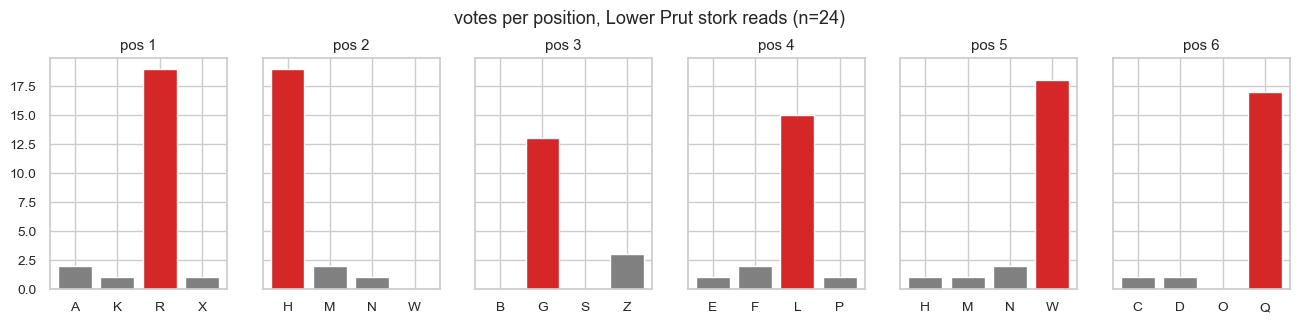

consensus: RHGLWQ


,position,group,consensus,votes,readable,runner_up,unreadable,all_votes
0,1,AKRX,R,19,23,A (2),1,R:19 A:2 K:1 X:1
1,2,HMNW,H,19,22,M (2),2,H:19 M:2 N:1
2,3,BGSZ,G,13,16,Z (3),8,G:13 Z:3
3,4,EFLP,L,15,19,F (2),5,L:15 F:2 P:1 E:1
4,5,HMNW,W,18,22,N (2),2,W:18 N:2 H:1 M:1
5,6,CDOQ,Q,17,19,D (1),5,Q:17 D:1 C:1


In [12]:
votes = pd.DataFrame([[s[p] for p in range(6)] for s in odd.ring_read])
tab = {p: votes[p][votes[p] != '?'].value_counts() for p in range(6)}
rows = []
for p in range(6):
    v = tab[p]; g = GR[gid[ix[v.index[0]]]]
    rows.append(dict(position=p + 1, group=g, consensus=v.index[0], votes=v.iloc[0], readable=v.sum(),
                     runner_up=(v.index[1] + f' ({v.iloc[1]})') if len(v) > 1 else '-',
                     unreadable=(votes[p] == '?').sum(), all_votes=' '.join(f'{k}:{n}' for k, n in v.items())))
cons = pd.DataFrame(rows)
WORD = ''.join(cons.consensus)
fig, ax = plt.subplots(1, 6, figsize=(16, 3), sharey=True)
for p in range(6):
    g = GR[gid[ix[cons.consensus[p]]]]
    ax[p].bar(list(g), [tab[p].get(c, 0) for c in g], color=['tab:red' if c == cons.consensus[p] else 'grey' for c in g])
    ax[p].set_title(f'pos {p + 1}')
plt.suptitle(f'votes per position, Lower Prut stork reads (n={len(odd)})', y=1.04); plt.show()
print('consensus:', WORD)
cons

In [13]:
supp = odd.ring_read.map(lambda s: sum(a != '?' and a != b for a, b in zip(s, WORD)))
print('reads that agree with', WORD, 'on every readable letter:', (supp == 0).sum(), '| one letter off:', (supp == 1).sum(), '| two off:', (supp == 2).sum())
eps = 1 - cons.votes.sum() / cons.readable.sum()
print('letters that disagree with the consensus:', round(eps, 3))
from math import comb
for p in range(6):
    n, k = cons.readable[p], cons.votes[p]
    q = 1 - sum(comb(n, i) * (1 / 4) ** i * (3 / 4) ** (n - i) for i in range(k))
    print(f'pos {p + 1}: {k}/{n} for {cons.consensus[p]}  (chance level 1/4, P(>= {k} by chance) = {q:.1e})')

reads that agree with RHGLWQ on every readable letter: 10 | one letter off: 8 | two off: 6
letters that disagree with the consensus: 0.165
pos 1: 19/23 for R  (chance level 1/4, P(>= 19 by chance) = 1.1e-08)
pos 2: 19/22 for H  (chance level 1/4, P(>= 19 by chance) = 2.5e-09)
pos 3: 13/16 for G  (chance level 1/4, P(>= 13 by chance) = 3.8e-06)
pos 4: 15/19 for L  (chance level 1/4, P(>= 15 by chance) = 1.2e-06)
pos 5: 18/22 for W  (chance level 1/4, P(>= 18 by chance) = 3.6e-08)
pos 6: 17/19 for Q  (chance level 1/4, P(>= 17 by chance) = 5.8e-09)


In [14]:
odd_ = odd.ring_read.tolist()
minor = [{(p, c) for p, c in enumerate(s) if c != '?' and c != WORD[p]} for s in odd_]
shared = max(len(a & b) for a, b in itertools.combinations(minor, 2))
print('largest number of identical off-consensus letters shared by two reads:', shared)
print('reads per year:', pd.to_datetime(odd.date).dt.year.value_counts().sort_index().to_dict())

largest number of identical off-consensus letters shared by two reads: 1
reads per year: {2016: 1, 2017: 1, 2018: 2, 2019: 3, 2020: 2, 2021: 2, 2022: 2, 2024: 6, 2025: 5}


Every position has a large majority: the consensus letter takes 79–89% of the readable votes, against 25% expected for a random group member, and no runner-up gets more than three votes. No two reads share more than one off-consensus letter, so the minority letters do not form a second ring: this is one bird.

The consensus `RHGLWQ` is what observers *see* at this site. The platform rejected it as the ring, which fits the site-swap picture: the Lower Prut site swaps letters like most sites do.

## 6. The Lower Prut swap

Registered birds let us measure the swap at other sites. Nothing registered is read at L5819951, so its swap has to be inferred from how swaps are built elsewhere and from the noise in the 24 reads.

In [15]:
PAIR = {1: [(0, 1), (2, 3)], 2: [(0, 2), (1, 3)], 3: [(0, 3), (1, 2)]}
EFF = {'a': [3, 2, 3, 0, 0, 0], 'b': [1, 1, 2, 0, 0, 0], 'd': [0, 0, 0, 3, 1, 2], 'e': [0, 0, 0, 1, 3, 3]}
def kind(t, r):
    if t == r: return 0
    g = GR[gid[ix[t]]]; i, j = sorted((g.index(t), g.index(r)))
    return [k for k, v in PAIR.items() if (i, j) in v][0]
def swap(ch, k):
    g = GR[gid[ix[ch]]]; i = g.index(ch)
    for u, v in PAIR.get(k, []):
        if i in (u, v): return g[v if i == u else u]
    return ch
def decode(word, effs):
    out = ''
    for ch in word:
        k = 0
        for e in effs: k ^= EFF[e][gid[ix[ch]]]
        out += swap(ch, k)
    return out

ok = rd[(rd.p_best > .99) & (rd.llr > 0)]
K = pd.DataFrame([(x.locality_id, gid[ix[b]], kind(b, a)) for x in ok.itertuples()
                  for a, b in zip(x.ring_read, x.best) if a != '?'], columns=['locality', 'g', 'k'])
print('true -> read inside a group, by pairing (0 = correct):')
print(pd.crosstab(K.g.map(dict(enumerate(GR))), K.k).to_string())

true -> read inside a group, by pairing (0 = correct):
k        0    1    2    3
g                        
AKRX   813  570  552  462
BGSZ   938  614  619  445
CDOQ   973  505  630  516
EFLP  1016  551  310  295
HMNW   939  336  398  500
IJTY  1316  310  343  598


Inside a group the letters are taken in alphabetical order (index 0–3). Every swap seen is one of the three ways to pair four letters: (01)(23), (02)(13), (03)(12), i.e. index XOR 1, 2 or 3. No 4-cycles or shifts: a site applies a fixed involution per group, not a rotating cipher.

Per site I fit four switchable components plus uniform in-group noise: `a`, `b` act on AKRX/BGSZ/CDOQ (first half), `d`, `e` on EFLP/HMNW/IJTY (second half).

In [16]:
grid = np.linspace(0, 1, 21); egrid = np.linspace(0, .6, 13)
def fit_half(cnt, e1, e2, gs):
    best = (-1e18, None)
    for p1, p2, ep in itertools.product(grid, grid, egrid):
        ll = 0
        for g in gs:
            pr = np.zeros(4); pr[0] += (1 - p1) * (1 - p2); pr[EFF[e1][g]] += p1 * (1 - p2)
            pr[EFF[e2][g]] += (1 - p1) * p2; pr[EFF[e1][g] ^ EFF[e2][g]] += p1 * p2
            ll += (cnt[g] * np.log((1 - ep) * pr + ep / 4 + 1e-12)).sum()
        if ll > best[0]: best = (ll, (p1, p2, ep))
    return best[1]
fits = []
for l, d in K.groupby('locality'):
    if len(d) < 40: continue
    cnt = {g: np.bincount(d[d.g == g].k, minlength=4) for g in range(6)}
    fits.append((l, len(d)) + fit_half(cnt, 'a', 'b', [0, 1, 2]) + fit_half(cnt, 'd', 'e', [3, 4, 5]))
F = pd.DataFrame(fits, columns=['locality', 'n', 'pa', 'pb', 'eps1', 'pd', 'pe', 'eps2']).set_index('locality')
HT = {(0, 0): '0', (0, 1): 'X', (1, 1): 'Y', (1, 0): 'Z'}
F['h1'] = [HT[(a >= .5, b >= .5)] for a, b in zip(F.pa, F.pb)]
F['h2'] = [HT[(d >= .5, e >= .5)] for d, e in zip(F['pd'], F.pe)]
print(len(F), 'sites with >= 40 read letters; swap type per half (rows: first half, cols: second half)')
print(pd.crosstab(F.h1, F.h2).to_string())

59 sites with >= 40 read letters; swap type per half (rows: first half, cols: second half)
h2   0   X  Y  Z
h1              
0   18   0  1  9
X    1  13  0  0
Y    0   0  6  1
Z    5   5  0  0


Half types: `0` none, `X` = b / e, `Y` = a+b / d+e, `Z` = a / d. The two halves are strongly tied: X goes with X, Y with Y, Z with an untouched other half (or with X at a few noisy sites). A site swap is close to one of a handful of whole-site types, `X|X` being the most common.

The noise tells which halves of the Lower Prut site are swapped: untouched halves are almost noise-free, swapped halves are not.

Lower Prut, consensus taken as seen letters: components (np.float64(0.05), np.float64(0.0), np.float64(0.05), np.float64(0.0)) noise per half (np.float64(0.15), np.float64(0.15))


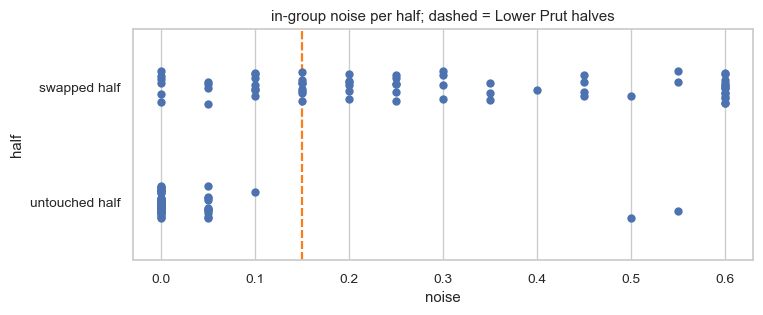

                count   mean   max
half                              
swapped half       66  0.292  0.60
untouched half     52  0.033  0.55


In [17]:
cc = {g: np.zeros(4, int) for g in range(6)}
for s in odd_:
    for a, b in zip(s, WORD):
        if a != '?': cc[gid[ix[b]]][kind(b, a)] += 1
pa, pb, e1 = fit_half(cc, 'a', 'b', [0, 1, 2]); pd_, pe, e2 = fit_half(cc, 'd', 'e', [3, 4, 5])
print('Lower Prut, consensus taken as seen letters: components', (pa, pb, pd_, pe), 'noise per half', (e1, e2))
H = pd.concat([pd.DataFrame(dict(noise=F.eps1, swapped=F.h1 != '0')), pd.DataFrame(dict(noise=F.eps2, swapped=F.h2 != '0'))])
H['half'] = np.where(H.swapped, 'swapped half', 'untouched half')
fig, ax = plt.subplots(figsize=(8, 3))
sns.stripplot(data=H, x='noise', y='half', size=6, jitter=.15, ax=ax)
for e, c in [(e1, 'tab:red'), (e2, 'tab:orange')]: ax.axvline(e, color=c, ls='--')
ax.set_title('in-group noise per half; dashed = Lower Prut halves'); plt.show()
print(H.groupby('half').noise.agg(['count', 'mean', 'max']).round(3))

Both Lower Prut halves carry ~15% noise. Of 52 untouched halves at calibrated sites, 50 have under 10% noise; the other two are so noisy (0.5 and more) that their swap cannot be read at all. So both Lower Prut halves are swapped: identity (`RHGLWQ`, rejected), `Z|0` and `0|Z` drop out. The remaining types are weighted by how often they occur at sites with low enough noise to classify (both halves ≤ 0.35), with half a count of smoothing, times the empirical chance that a half of that status shows ≥ 10% noise.

In [18]:
TO_EFF = [{'0': [], 'X': ['b'], 'Y': ['a', 'b'], 'Z': ['a']}, {'0': [], 'X': ['e'], 'Y': ['d', 'e'], 'Z': ['d']}]
clean = F[(F.eps1 <= .35) & (F.eps2 <= .35)]
n_pair = pd.crosstab(clean.h1, clean.h2)
p_noisy = {s: ((H[H.swapped == s].noise >= .1).sum() + .5) / ((H.swapped == s).sum() + 1) for s in (True, False)}
rows = []
for h1, h2 in itertools.product('0XYZ', repeat=2):
    if (h1, h2) == ('0', '0'): continue
    n = n_pair.loc[h1, h2] if h1 in n_pair.index and h2 in n_pair.columns else 0
    w = (n + .5) * p_noisy[h1 != '0'] * p_noisy[h2 != '0']
    effs = TO_EFF[0][h1] + TO_EFF[1][h2]
    rows.append(dict(swap=h1 + '|' + h2, components='+'.join(effs), sites=n, ring=decode(WORD, effs), weight=w))
cand_t = pd.DataFrame(rows)
cand_t['p'] = (cand_t.weight / cand_t.weight.sum()).round(3)
cand_t = cand_t.sort_values('p', ascending=False).reset_index(drop=True)
cand_t[['swap', 'components', 'sites', 'ring', 'p']].head(8)

,swap,components,sites,ring,p
0,X|X,b+e,9,XWBPHD,0.491
1,Y|Y,a+b+d+e,3,ANSEMO,0.181
2,Y|Z,a+b+d,1,AMSFNO,0.078
3,Z|X,a+e,1,KWZPHC,0.078
4,X|Y,b+d+e,0,XNBEMD,0.026
5,X|Z,b+d,0,XMBFND,0.026
6,Y|X,a+b+e,0,AWSPHO,0.026
7,Z|Y,a+d+e,0,KNZEMC,0.026


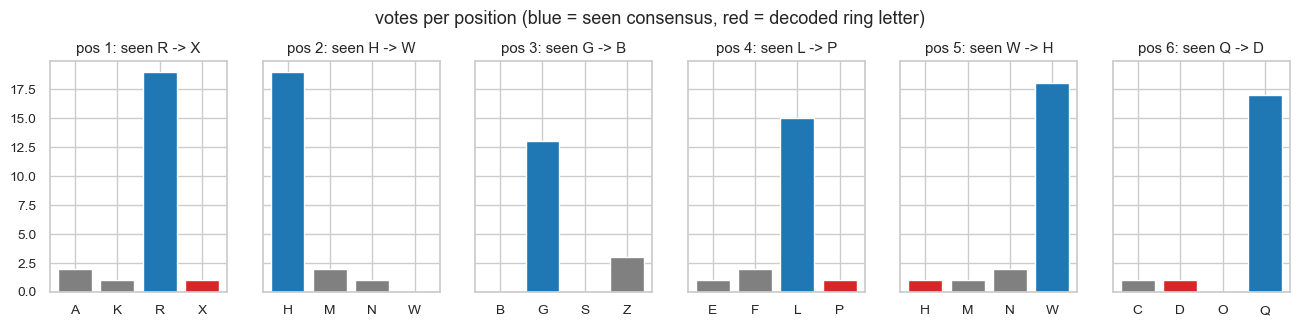

,0,1,2,3,4,5
seen,R,H,G,L,W,Q
ring,X,W,B,P,H,D
group,AKRX,HMNW,BGSZ,EFLP,HMNW,CDOQ
pairing,1,3,1,1,3,2


In [19]:
RING = cand_t.ring[0]
check = pd.DataFrame(dict(seen=list(WORD), ring=list(RING), group=[GR[gid[ix[c]]] for c in WORD]))
check['pairing'] = [kind(s, r) for s, r in zip(WORD, RING)]
fig, ax = plt.subplots(1, 6, figsize=(16, 3), sharey=True)
for p in range(6):
    g = GR[gid[ix[WORD[p]]]]
    ax[p].bar(list(g), [tab[p].get(c, 0) for c in g],
              color=['tab:red' if c == RING[p] else ('tab:blue' if c == WORD[p] else 'grey') for c in g])
    ax[p].set_title(f'pos {p + 1}: seen {WORD[p]} -> {RING[p]}')
plt.suptitle('votes per position (blue = seen consensus, red = decoded ring letter)', y=1.05); plt.show()
check.T

`X|X` (components b+e) is the most common whole-site swap among the calibrated sites, and its two halves always come together. Decoding the seen consensus through it gives the ring below. The rest of the probability goes mostly to the `Y|Y` type (`ANSEMO`) and the mixed `Z|X` type (`KWZPHC`).

## Answer

In [20]:
print('ring:', RING)
print('flag: SIGMOID_' + RING)
cand_t[['ring', 'swap', 'p']].head(5)

ring: XWBPHD
flag: SIGMOID_XWBPHD


,ring,swap,p
0,XWBPHD,X|X,0.491
1,ANSEMO,Y|Y,0.181
2,AMSFNO,Y|Z,0.078
3,KWZPHC,Z|X,0.078
4,XNBEMD,X|Y,0.026
